# 01 · ETL y calidad de los datos

**Objetivo:** construir un dataset diario fiable a partir de fuentes públicas y documentar cada decisión de limpieza que pide el enunciado (festivos distintos en cada mercado, días sin cotización y *outliers*).

```
 EXTRACCIÓN                         TRANSFORMACIÓN                            CARGA
 FRED  (7 series, sin rellenar) ─┐   1. Filas = días con Brent real (EIA)       data/raw/fred.csv
                                 ├─> 2. Resto de series: último valor conocido ─> data/raw/yahoo.csv
 Yahoo (6 tickers, OHLCV/cierre) ┘   3. Nunca se rellena hacia atrás             data/petroleo_dataset.csv
                                                                                data/metadata.json
```

Todo el proceso está en `src/oil_forecast/data.py` y se ejecuta con:

```bash
poetry run python scripts/download_data.py
```

Este notebook **no descarga nada**: trabaja sobre los ficheros generados por el script para que el análisis sea reproducible.

In [1]:
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oil_forecast.config import TARGET
from oil_forecast.data import FRED_SERIES, YAHOO_CLOSE, YAHOO_OHLCV, load_dataset, load_metadata, load_raw

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 80, "axes.titlesize": 12})
pd.set_option("display.float_format", "{:.2f}".format)

fred, yahoo = load_raw()
data = load_dataset()
meta = load_metadata()
print(f"Descarga: {meta['downloaded_at']} · último Brent publicado: {meta['last_brent_date']}")

Descarga: 2026-11-05T18:26:40 · último Brent publicado: 2026-11-03


## 1. Extracción: qué se descarga

| Fuente | Serie | Columna | Papel |
|---|---|---|---|
| EIA vía FRED | `DCOILBRENTEU` | `brent` | **Variable objetivo** (Brent spot, $/barril) |
| EIA vía FRED | `DCOILWTICO` | `wti` | Referencia americana |
| EIA vía FRED | `DHHNGSP` | `gas_natural` | Gas natural Henry Hub (spot) |
| BCE vía FRED | `ECBDFR` | `tipo_bce` | Política monetaria europea |
| Fed vía FRED | `DEXUSEU`, `DEXCHUS` | `usd_por_eur`, `cny_por_usd` | Tipos de cambio |
| Cboe vía FRED | `VIXCLS` | `vix` | Aversión al riesgo |
| Yahoo | `BZ=F`, `CL=F` | `brent_fut_*`, `wti_fut_*` | Futuros (apertura, máximo, mínimo, cierre, volumen) |
| Yahoo | `NG=F` | `gas_fut` | Futuro de gas natural (**añadido**, ver sección 4) |
| Yahoo | `HG=F`, `GC=F`, `DX-Y.NYB` | `cobre`, `oro`, `indice_dolar` | Actividad industrial, refugio, dólar |

La **cesta de la OPEP** no se incluye: la web de la OPEP bloquea la descarga automática (protección anti-bots), por lo que no se puede integrar en una actualización periódica fiable, y está casi perfectamente correlacionada con el Brent (es una media de crudos que cotizan con referencia a él), así que aportaría muy poca información nueva.

In [2]:
raw = pd.concat([fred, yahoo], axis=1, sort=True)
cols = list(FRED_SERIES.values()) + [f"{p}_Close" for p in YAHOO_OHLCV.values()] + list(YAHOO_CLOSE.values())
summary = pd.DataFrame({
    "fuente": ["FRED"] * len(FRED_SERIES) + ["Yahoo"] * (len(cols) - len(FRED_SERIES)),
    "primer dato": [raw[c].first_valid_index().date() for c in cols],
    "último dato": [raw[c].last_valid_index().date() for c in cols],
    "observaciones": [raw[c].notna().sum() for c in cols],
}, index=cols)
summary

,fuente,primer dato,último dato,observaciones
brent,FRED,2000-01-04,2026-11-03,6501
wti,FRED,2000-01-04,2026-11-03,6352
gas_natural,FRED,2000-01-10,2026-11-03,5427
tipo_bce,FRED,2000-01-01,2026-11-05,9806
usd_por_eur,FRED,2000-01-03,2026-10-30,6727
cny_por_usd,FRED,2000-01-03,2026-10-30,6728
vix,FRED,2000-01-03,2026-11-04,6785
brent_fut_Close,Yahoo,2007-07-30,2026-11-05,4798
wti_fut_Close,Yahoo,2000-08-23,2026-11-05,6580
gas_fut,Yahoo,2000-08-30,2026-11-05,6577


## 2. Cobertura: ¿cuántos datos reales hay cada año?

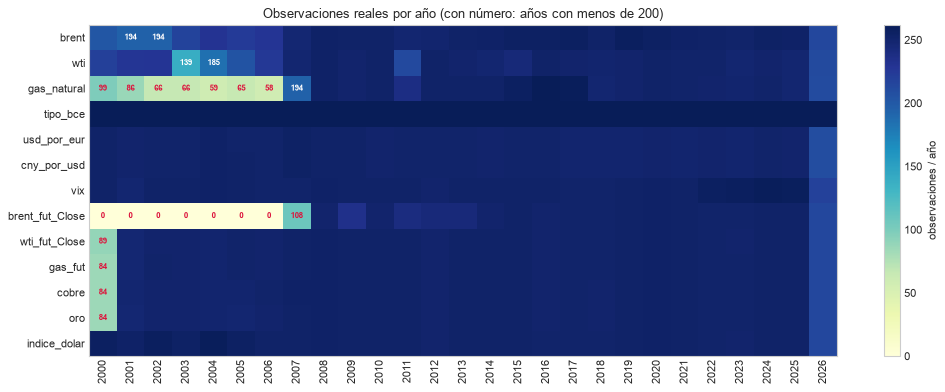

In [3]:
counts = raw[cols].notna().groupby(raw.index.year).sum().T
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(counts, aspect="auto", cmap="YlGnBu", vmin=0, vmax=262)
ax.set_yticks(range(len(cols)), cols)
ax.set_xticks(range(len(counts.columns)), counts.columns, rotation=90)
for i in range(len(cols)):
    for j in range(len(counts.columns)):
        v = counts.iloc[i, j]
        if v < 200:
            ax.text(j, i, v, ha="center", va="center", fontsize=7, fontweight="bold",
                    color="white" if v > 130 else "crimson")
ax.grid(False)
fig.colorbar(im, label="observaciones / año")
ax.set_title("Observaciones reales por año (con número: años con menos de 200)")
plt.tight_layout()

**Observaciones:**
- La mayoría de series tiene ~250 cotizaciones al año (días hábiles). El Brent y el WTI de la EIA tienen algunos años de principios de los 2000 con menos publicaciones (huecos de la propia fuente, no del proceso).
- El **futuro del Brent `BZ=F` no existe antes de agosto de 2007** → no se puede usar como entrada sin perder 7 años de historia.
- Los futuros de Yahoo (WTI, gas, cobre, oro) empiezan en **agosto de 2000**.
- El **gas Henry Hub spot tiene muy pocos datos hasta 2007** (≈60-100 al año): la EIA no lo publicaba a diario. Se analiza en la sección 4.
- `tipo_bce` tiene 365 datos al año porque FRED lo publica también en fines de semana (es un tipo vigente, no una cotización).
- 2026 está incompleto (datos hasta noviembre).

## 3. Calendario: el problema del script original

El script inicial unía todos los mercados con un `outer join`, rellenaba hacia delante y **después** eliminaba las filas sin Brent. Como el relleno se hacía antes, el Brent se copiaba en días en que **no cotizó** (festivos del Reino Unido, días con datos solo de EE. UU., y días aún no publicados por la EIA). Reconstruimos ese procedimiento con los datos originales para cuantificarlo.

In [4]:
original = pd.concat([fred, yahoo], axis=1, sort=True).ffill().dropna(subset=[TARGET])
original = original[original.index.day_of_week < 5].loc["2000-01-01":]
fake = original.index.difference(data.index)

zero_orig = (original[TARGET].diff() == 0).mean()
zero_new = (data[TARGET].diff() == 0).mean()
print(f"Procedimiento original: {len(original):,} filas · nuevo ETL: {len(data):,} filas")
print(f"Días ficticios eliminados: {len(fake)} ({len(fake) / len(original):.1%})")
print(f"Días con variación del Brent exactamente 0: original {zero_orig:.1%} → nuevo {zero_new:.1%}")
print(f"Últimas filas del procedimiento original: {', '.join(f'{d:%d/%m}' for d in original.index[-3:])}"
      f" · último Brent real: {data.index[-1]:%d/%m/%Y}")

Procedimiento original: 7,003 filas · nuevo ETL: 6,501 filas
Días ficticios eliminados: 502 (7.2%)
Días con variación del Brent exactamente 0: original 8.2% → nuevo 1.1%
Últimas filas del procedimiento original: 03/11, 04/11, 05/11 · último Brent real: 03/11/2026


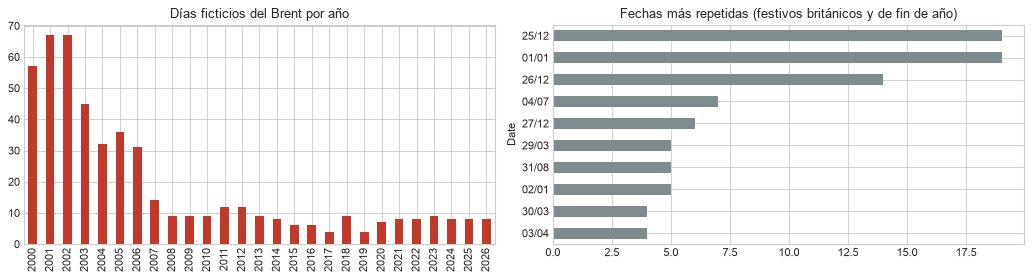

In [5]:
fake_s = fake.to_series()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
fake_s.groupby(fake_s.dt.year).size().plot(kind="bar", ax=axes[0], color="#c0392b")
axes[0].set_title("Días ficticios del Brent por año"); axes[0].set_xlabel("")
(fake_s.dt.strftime("%d/%m").value_counts().head(10)).plot(kind="barh", ax=axes[1], color="#7f8c8d")
axes[1].set_title("Fechas más repetidas (festivos británicos y de fin de año)"); axes[1].invert_yaxis()
plt.tight_layout()

**Conclusión:** el 7 % de las filas eran días inventados para el Brent, con retorno 0. Eso habría reducido artificialmente la volatilidad y enseñado a la red un patrón falso ("a veces el precio no se mueve"). El nuevo ETL usa **solo los días en que la EIA publicó el Brent**; el resto de variables toman su último valor conocido ese día.

## 4. Antigüedad del dato: ¿cuánto de "viejo" es el valor que usamos?

Al alinear con el calendario del Brent, cada variable externa toma su último valor disponible. Medimos cuántos días naturales tiene ese valor en cada fecha (0 = dato del mismo día).

In [6]:
brent_days = fred[TARGET].dropna().index
rows = {}
for c in cols[1:]:
    obs = raw[c].dropna()
    last_seen = pd.Series(obs.index, index=obs.index).reindex(brent_days.union(obs.index)).ffill().reindex(brent_days)
    age = (brent_days - last_seen).dt.days[brent_days >= obs.index.min()]
    rows[c] = {"mismo día %": (age == 0).mean() * 100, "media (días)": age.mean(),
               "p99 (días)": age.quantile(0.99), "máximo (días)": age.max(), "> 5 días": int((age > 5).sum())}
staleness = pd.DataFrame(rows).T
staleness

,mismo día %,media (días),p99 (días),máximo (días),> 5 días
wti,93.22,0.15,3.00,7.00,11.00
gas_natural,81.16,1.17,18.00,40.00,504.00
tipo_bce,100.00,0.00,0.00,0.00,0.00
usd_por_eur,97.49,0.06,3.00,4.00,0.00
cny_por_usd,97.51,0.06,3.00,4.00,0.00
vix,98.69,0.03,1.00,4.00,0.00
brent_fut_Close,97.48,0.07,3.00,16.00,9.00
wti_fut_Close,98.12,0.04,3.00,4.00,0.00
gas_fut,98.15,0.04,3.00,4.00,0.00
cobre,98.10,0.04,3.00,4.00,0.00


Correlación de retornos diarios spot vs futuro: 0.15


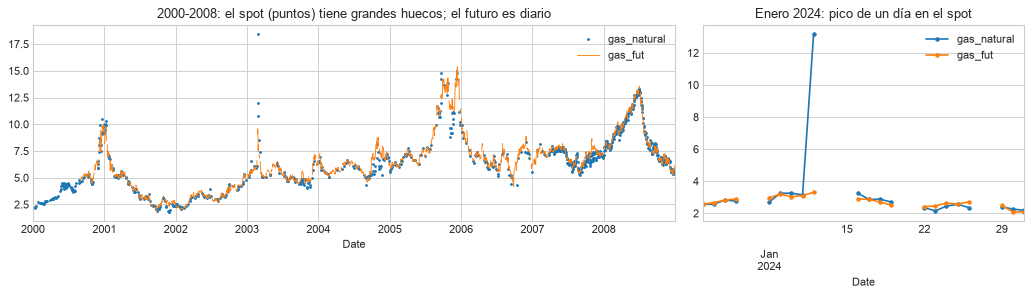

In [7]:
gas = pd.concat([raw["gas_natural"], raw["gas_fut"]], axis=1, sort=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})
gas.loc["2000":"2008"].plot(ax=axes[0], style=[".", "-"], ms=3, lw=0.8)
axes[0].set_title("2000-2008: el spot (puntos) tiene grandes huecos; el futuro es diario")
gas.loc["2024-01-02":"2024-01-31"].plot(ax=axes[1], marker="o", ms=3)
axes[1].set_title("Enero 2024: pico de un día en el spot")
plt.tight_layout()
r = np.log(gas).diff().dropna()
print(f"Correlación de retornos diarios spot vs futuro: {r.corr().iloc[0, 1]:.2f}")

**Conclusiones:**
- La mayoría de variables tiene el dato del mismo día (o del día hábil anterior en festivos de EE. UU.): en más del 97 % de los días el dato es del mismo día y el máximo es de 4 días (7 en el WTI spot, que solo se usa para el diferencial).
- El **gas Henry Hub spot** llega a usar valores de **40 días de antigüedad** antes de 2007, tiene picos de un solo día (13,20 $ el 12/01/2024 frente a ~3 $ alrededor, un efecto de entrega en fin de semana durante una ola de frío) y su retorno apenas correlaciona con el del futuro (0,15). **Decisión: para modelar se usa el futuro `NG=F` (`gas_fut`)**, que es diario, líquido y refleja lo que el mercado espera; el spot se conserva en el dataset solo como referencia.
- El futuro del Brent tiene huecos puntuales de hasta 16 días en Yahoo y empieza en 2007: no se usa como entrada.

## 5. Outliers: ¿errores o realidad?

El enunciado pide tratar explícitamente el WTI negativo (20/04/2020), el máximo de 2008 y los picos de 2022 y 2026. Distinguimos dos tipos:
- **Outliers en nivel** (precios extremos): son la realidad del mercado y lo que el modelo debe aprender a soportar.
- **Outliers en retorno diario**: movimientos de un día anormalmente grandes. Los detectamos con un *z-score* robusto (mediana y MAD), que no se deja contaminar por los propios extremos.

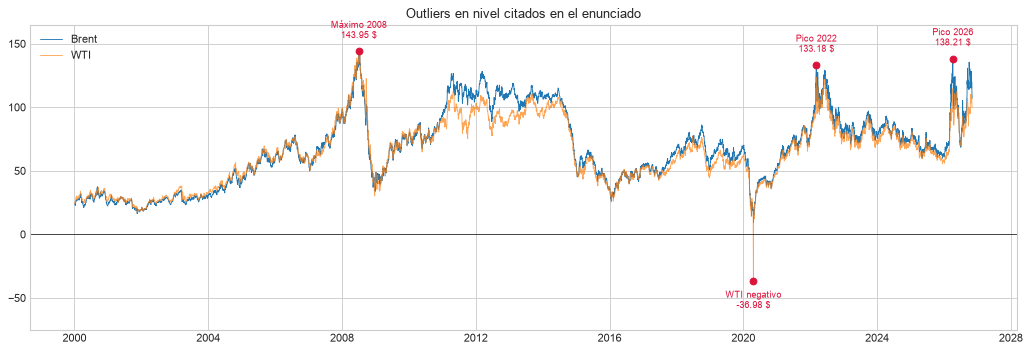

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(data.index, data[TARGET], lw=0.8, label="Brent")
ax.plot(data.index, data["wti"], lw=0.8, alpha=0.7, label="WTI")
marks = {"2008-07-03": "Máximo 2008", "2020-04-20": "WTI negativo", "2022-03-08": "Pico 2022", "2026-04-07": "Pico 2026"}
for d, label in marks.items():
    d = pd.Timestamp(d)
    col = "wti" if "WTI" in label else TARGET
    v = data[col].asof(d)
    ax.scatter(d, v, color="crimson", zorder=3)
    ax.annotate(f"{label}\n{v:.2f} $", (d, v), xytext=(0, 12 if v > 0 else -24), textcoords="offset points",
                ha="center", fontsize=8, color="crimson")
ax.axhline(0, color="k", lw=0.6); ax.legend(); ax.set_ylim(-75, 165)
ax.set_title("Outliers en nivel citados en el enunciado")
plt.tight_layout()

In [9]:
def robust_z(r):
    med = r.median()
    return (r - med) / (1.4826 * (r - med).abs().median())

events = []
for c in [TARGET, "wti", "wti_fut_Close", "gas_natural", "gas_fut", "oro", "cobre", "indice_dolar", "usd_por_eur", "cny_por_usd", "vix"]:
    obs = raw[c].dropna()
    r = np.log(obs.where(obs > 0)).diff().dropna()
    z = robust_z(r)
    for d in z.abs().nlargest(2).index:
        events.append({"serie": c, "fecha": d.date(), "retorno %": r[d] * 100, "z robusto": z[d]})
outliers = pd.DataFrame(events)
outliers

,serie,fecha,retorno %,z robusto
0,brent,2020-04-21,-64.37,-35.38
1,brent,2020-04-22,41.20,22.58
2,wti,2020-04-22,42.58,21.37
3,wti,2020-03-31,37.47,18.80
4,wti_fut_Close,2020-04-22,31.96,16.33
5,wti_fut_Close,2020-03-09,-28.22,-14.52
6,gas_natural,2024-01-12,143.28,43.56
7,gas_natural,2024-01-16,-140.16,-42.61
8,gas_fut,2026-01-29,-64.40,-21.96
9,gas_fut,2022-01-27,38.17,13.04


Interpretación de los principales:

| Serie | Fecha | Qué pasó |
|---|---|---|
| Brent / WTI | marzo-abril 2020 | Pandemia y guerra de precios Arabia Saudí-Rusia; WTI negativo por falta de almacenamiento al vencer el futuro |
| CNY/USD | 22/07/2005 y 11/08/2015 | Fin de la paridad fija con el dólar y devaluación sorpresa del yuan |
| VIX | 05/02/2018 | "Volmageddon": colapso de los productos que vendían volatilidad |
| Cobre | 31/07/2025 | Exención de aranceles de EE. UU. al cobre refinado, que hundió la prima del COMEX |
| Oro | 30/01/2026 | Mayor caída diaria en décadas tras máximos históricos (~5.600 $/oz), con toma de beneficios y el nombramiento del nuevo presidente de la Fed |
| Gas spot | 12-16/01/2024 | Pico de un día durante una ola de frío (precio negociado el viernes para entrega en fin de semana) |
| Gas futuro | 27/01/2022 y 29/01/2026 | **Artefacto de la serie continua**: el contrato que vence sube con fuerza el último día (en 2026, tras una tormenta invernal, cerró a 7,46 $) y al día siguiente Yahoo pasa al contrato siguiente (3,92 $). Ese −64 % no lo sufrió ningún contrato real |

Todos son hechos de mercado salvo el último tipo: los **saltos por cambio de contrato** de las series continuas de futuros. Afectan a cualquier futuro de Yahoo (también al WTI) aunque normalmente son pequeños; la winsorización de las entradas limita los grandes.

**Política de tratamiento (se aplica en el preprocesamiento, no aquí):**
1. **No se elimina ningún día**: borrar 2020 o 2026 sería esconderle al modelo exactamente las situaciones en las que más importa acertar.
2. **Variable objetivo (Brent) intacta**: se evalúa contra la realidad.
3. **Entradas winsorizadas** con los percentiles 0,5 % y 99,5 % calculados **solo con el train de cada fold** (así un día como el 21/04/2020 no domina el entrenamiento).
4. **WTI negativo**: su logaritmo no existe → el retorno de ese día queda sin definir y se usa el valor anterior. Además, el WTI spot solo se usa para el diferencial Brent-WTI; los retornos se calculan con el futuro.
5. Se trabaja con **retornos**, no con niveles: un precio de 138 $ no es un outlier en retorno si se llegó a él de forma gradual.

## 6. Retrasos de publicación y horarios de cierre

In [10]:
last = pd.Series(meta["last_observation"]).pipe(pd.to_datetime)
lag = (pd.Timestamp(meta["downloaded_at"]).normalize() - last).dt.days
pd.DataFrame({"último dato": last.dt.date, "días de retraso": lag}).loc[cols]

,último dato,días de retraso
brent,2026-11-03,2
wti,2026-11-03,2
gas_natural,2026-11-03,2
tipo_bce,2026-11-05,0
usd_por_eur,2026-10-30,6
cny_por_usd,2026-10-30,6
vix,2026-11-04,1
brent_fut_Close,2026-11-05,0
wti_fut_Close,2026-11-05,0
gas_fut,2026-11-05,0


**Observaciones:**
- **El Brent de la EIA se publica con 1-2 días de retraso**: la predicción siempre se hace desde el último dato real, no desde "hoy". La app mostrará esa fecha.
- **Los tipos de cambio de FRED se publican semanalmente** (con hasta una semana de retraso): en tiempo real el último valor estará algo desfasado. Tiene poco impacto porque se mueven poco en una semana.
- **Horarios:** el Brent spot se fija al cierre de Londres; los mercados de EE. UU. (futuros, VIX, índice dólar) cierran unas horas después **el mismo día**. Como la predicción se hace al final del día *t* para fechas *t+5* o posteriores, usar los cierres de EE. UU. del día *t* es legítimo: toda esa información existe antes de que empiece *t+1*. (Este desfase horario explica por qué el WTI de ayer anticipa algo del Brent de hoy, ver notebook 02.)

## 7. Resultado: el dataset final

In [11]:
print(f"{data.shape[0]:,} días × {data.shape[1]} columnas · {data.index.min():%d/%m/%Y} - {data.index.max():%d/%m/%Y}")
missing = data.isna().sum()
pd.DataFrame({"nulos": missing, "primer dato": data.apply(lambda s: s.first_valid_index().date())})[missing > 0]

6,501 días × 21 columnas · 04/01/2000 - 03/11/2026


,nulos,primer dato
gas_natural,4,2000-01-10
brent_fut_Open,1629,2007-07-30
brent_fut_High,1629,2007-07-30
brent_fut_Low,1629,2007-07-30
brent_fut_Close,1629,2007-07-30
brent_fut_Volume,1629,2007-07-30
wti_fut_Open,133,2000-08-23
wti_fut_High,133,2000-08-23
wti_fut_Low,133,2000-08-23
wti_fut_Close,133,2000-08-23


Los únicos nulos que quedan son **inicios de serie** (Yahoo desde agosto de 2000, `BZ=F` desde 2007) y unos pocos días de gas spot al principio: nunca se rellenan hacia atrás porque eso sería inventar el pasado con información futura.

## Resumen de decisiones del ETL

| # | Decisión | Motivo |
|---|---|---|
| 1 | Filas = días con Brent publicado por la EIA | Evita ≈500 días ficticios con retorno 0 |
| 2 | Variables externas: último valor conocido (antigüedad máxima observada: 4 días; 7 en el WTI spot) | Festivos distintos en cada mercado; solo usa información pasada |
| 3 | Nunca se rellena hacia atrás | Evitar fugas de información |
| 4 | Gas: futuro `NG=F` en lugar del spot Henry Hub | Spot con huecos de hasta 40 días y picos de un día |
| 5 | Futuro del Brent `BZ=F` no se usa como entrada | Empieza en 2007 |
| 6 | Cesta OPEP excluida | No descargable de forma automática y casi idéntica al Brent |
| 7 | Outliers conservados; entradas winsorizadas por fold; objetivo intacto | Son hechos reales que el modelo debe soportar |
| 8 | Series originales guardadas en `data/raw/` y metadatos en `data/metadata.json` | Trazabilidad y control de la fecha del último dato real |